### Cloning the repo from GitHub

In [1]:
import os
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

%cd /content
if not os.path.exists('/content/3D_Perception'):
    !git clone https://github.com/giacomosalvatori03/3D_Perception.git
%cd /content/3D_Perception
!git pull
!git fetch origin
!git checkout project2-fusion
!git pull origin project2-fusion

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content
/content/3D_Perception
Already up to date.
Already on 'project2-fusion'
Your branch is up to date with 'origin/project2-fusion'.
From https://github.com/giacomosalvatori03/3D_Perception
 * branch            project2-fusion -> FETCH_HEAD
Already up to date.


In [1]:
import sys

!pip install ultralytics huggingface_hub -q

sys.path.insert(0, "/content/3D_Perception")
from src import CameraDetector

# Initialize the 2D detector with KITTI weights
detector_2d = CameraDetector(conf_thresh=0.25)

# Test inference on a validation frame
sample_img_path = (
    "/content/drive/MyDrive/3D_Perception/data/kitti_validation/image_2/000008.png"
)
detections_2d = detector_2d.detect(sample_img_path)

print(f"\n Found {len(detections_2d)} 2D detections in the image:")
for det in detections_2d:
    bbox = [round(v, 1) for v in det["bbox_2d"]]
    print(
        f"  - [{det['type']}] Confidence: {det['score']:.2f} | 2D BBox: {bbox}"
    )

 Downloading/Loading KITTI YOLOv8 model from HF: dronefreak/kitti-yolov8m/best.pt...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


 Loaded KITTI 2D Detector. Registered classes: {0: 'Car', 1: 'Cyclist', 2: 'Misc', 3: 'Pedestrian', 4: 'Person_sitting', 5: 'Tram', 6: 'Truck', 7: 'Van'}

 Found 9 2D detections in the image:
  - [Car] Confidence: 0.92 | 2D BBox: [884.5, 177.8, 954.4, 241.1]
  - [Car] Confidence: 0.89 | 2D BBox: [738.2, 168.2, 788.1, 209.1]
  - [Car] Confidence: 0.88 | 2D BBox: [594.4, 175.5, 719.0, 264.5]
  - [Car] Confidence: 0.86 | 2D BBox: [945.7, 200.9, 1242.0, 375.0]
  - [Car] Confidence: 0.83 | 2D BBox: [335.7, 173.7, 618.6, 366.1]
  - [Car] Confidence: 0.83 | 2D BBox: [861.7, 173.9, 887.3, 195.8]
  - [Car] Confidence: 0.81 | 2D BBox: [0.1, 174.4, 400.3, 374.6]
  - [Car] Confidence: 0.72 | 2D BBox: [765.9, 170.9, 803.8, 201.6]
  - [Car] Confidence: 0.30 | 2D BBox: [879.2, 181.7, 936.1, 228.3]


## Camera-only evaluation

In [2]:
!pip install ultralytics huggingface_hub -q

import sys
sys.path.insert(0, "/content/3D_Perception")

from validate_camera import CameraValidator

# Initialize the validation class
validator = CameraValidator(
    data_path="/content/drive/MyDrive/3D_Perception/data/kitti_validation",
    save_dir="/content/drive/MyDrive/3D_Perception/experiments_camera",
    conf_thresh=0.25,
)

# Run validation on all samples (or on max_samples for quick tests)
validator.validate(exp_name="yolov8m_baseline_2d", max_samples=500)

 Downloading/Loading KITTI YOLOv8 model from HF: dronefreak/kitti-yolov8m/best.pt...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


 Loaded KITTI 2D Detector. Registered classes: {0: 'Car', 1: 'Cyclist', 2: 'Misc', 3: 'Pedestrian', 4: 'Person_sitting', 5: 'Tram', 6: 'Truck', 7: 'Van'}

 Starting 2D Camera Validation [YOLOV8M_BASELINE_2D] | Samples: 500/3769
 Output destination: /content/drive/MyDrive/3D_Perception/experiments_camera/yolov8m_baseline_2d


Processing 2D Frames: 100%|██████████| 500/500 [15:16<00:00,  1.83s/it]


 2D Validation completed successfully!
  • Predictions saved in: /content/drive/MyDrive/3D_Perception/experiments_camera/yolov8m_baseline_2d/pred_labels
  • Ground Truths saved in: /content/drive/MyDrive/3D_Perception/experiments_camera/yolov8m_baseline_2d/gt_labels


In [4]:
import sys

sys.path.insert(0, "/content/3D_Perception")

from src import CameraEvaluator

# Initialize the 2D evaluator
evaluator_2d = CameraEvaluator()

# Compute the evaluation metrics on the 2D predictions
exp_dir = "/content/drive/MyDrive/3D_Perception/experiments_camera/yolov8m_baseline_2d"
df_results = evaluator_2d.evaluate(exp_dir)


 OVERALL 2D DETECTION mAP40 [yolov8m_baseline_2d]



,Easy,Moderate,Hard
Class,,,
Car,45.77%,64.57%,65.24%
Pedestrian,59.36%,52.33%,46.47%
Cyclist,50.44%,38.73%,37.25%



 Reports saved in '/content/drive/MyDrive/3D_Perception/experiments_camera/yolov8m_baseline_2d': .json, .csv, .md, .tex


### Visualize the camera-only

 2D Grid Visualization saved to Drive: /content/drive/MyDrive/3D_Perception/experiments_camera/yolov8m_baseline_2d/visualizations/summary_2d_grid.png


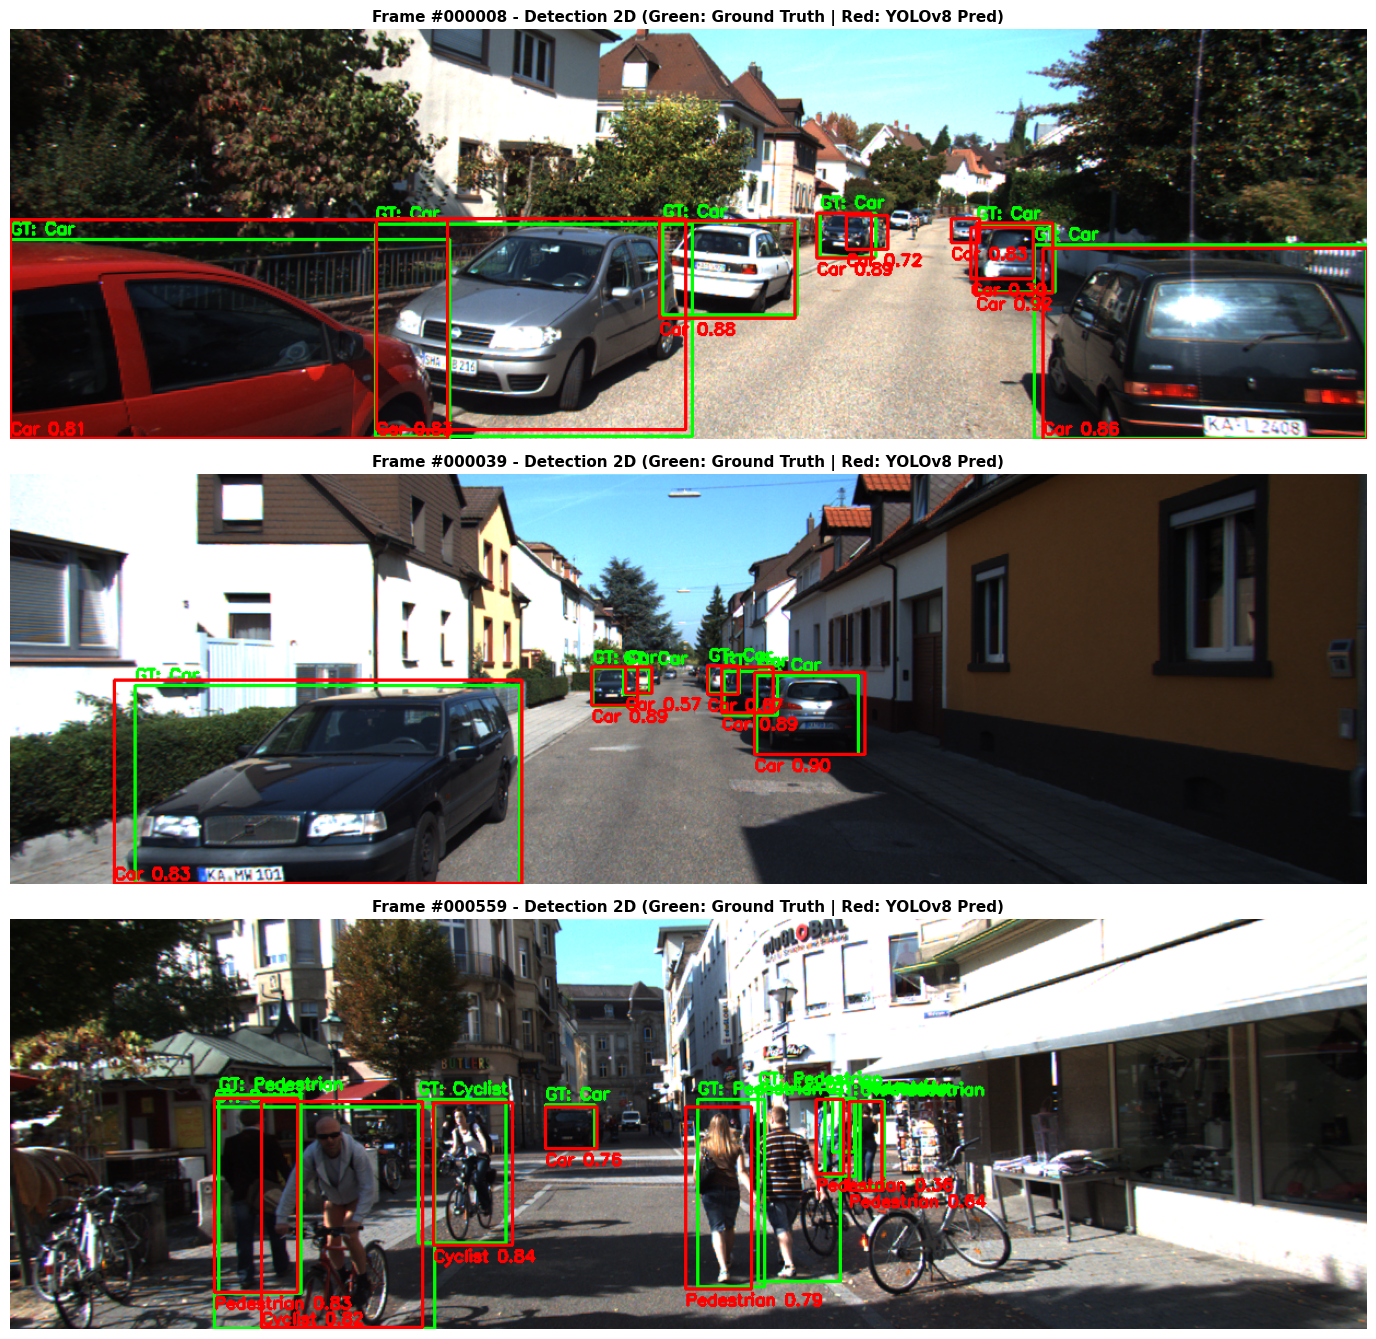

In [2]:
import sys

sys.path.insert(0, "/content/3D_Perception")

from scripts.camera_visualizer import CameraVisualizer

visualizer_2d = CameraVisualizer(
    data_path="/content/drive/MyDrive/3D_Perception/data/kitti_validation"
)

exp_dir = "/content/drive/MyDrive/3D_Perception/experiments_camera/yolov8m_baseline_2d"

# Visualize 3 significant samples from the experiment
visualizer_2d.visualize_experiment_2d(
    exp_dir=exp_dir,
    sample_ids=["000008", "000039", "000559"],  # You can pass specific IDs or leave as None
    save_plots=True,
)